<a href="https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ZeroGrad quickstart: from `pip install` to the podium

ZeroGrad runs a **championship** of tabular foundation models on your data: each model reads your labeled rows as context, all of them are scored on the same holdout, and the best one becomes your champion. Nothing to train.

A GPU runtime makes it faster (*Runtime → Change runtime type → T4 GPU*), but CPU works too.

In [1]:
!pip install -q zerograd

## What is there

Every model the SDK knows, with its license and whether you can use it commercially. Non-commercial models are off by default.

In [2]:
import zerograd
from zerograd import ZeroGrad

zerograd.list_models()

/home/runner/work/zerograd-python/zerograd-python/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model,Use,Tasks,Installed,remote=True,License · weights,Notes
TabICLv2tabicl-v2,Commercial use,classification regression anomaly_detection imputation synthetic_data,✓,✓,BSD-3-ClauseWeights: huggingface.co/jingang/TabICL,
TabPFN v2tabpfn-v2,Commercial use,classification regression anomaly_detection imputation synthetic_data,✓,✓,Prior Labs License v1.0 (Apache 2.0 with attribution)Weights: huggingface.co/Prior-Labs/TabPFN-v2-clf,Show: “Built with PriorLabs-TabPFN”
Mitra-v2mitra-v2,Commercial use,classification regression,"—pip install ""zerograd[mitra]""",—,Apache 2.0Weights: huggingface.co/autogluon/mitra-classifier-2,Zero-shot (no fine-tuning). The published benchmark numbers use fine-tuning with bagging on a GPU.
TabDPTtabdpt,Commercial use,classification regression,"—pip install ""zerograd[tabdpt]""",—,Apache 2.0Weights: huggingface.co/Layer6/TabDPT,
FoMo-0Dfomo-0d,Commercial use,anomaly_detection,✓,—,MITWeights: huggingface.co/YuchenShen/FoMo-0D,"Zero-shot outlier detection (Shen, Wen, Akoglu; CMU, ICML 2025). Up to 100 features; more are subsampled."
Mitramitra,Commercial use,classification regression,"—pip install ""zerograd[mitra]""",—,Apache 2.0Weights: huggingface.co/autogluon/mitra-classifier,
ZEUSzeus,Commercial use,clustering,✓,—,Apache 2.0Weights: github.com/gmum/zeus (checkpoint on the authors' Google Drive),"Zero-shot embeddings for clustering (Marszałek et al., Jagiellonian University, 2025), clustered with k-means. Embeds up to 2,000 rows at once."
EXAONE Tabular (LG)exaone-tabular,Non-commercial,classification regression,"—pip install ""exaonetabular @ git+https://github.com/LGAI-Research/EXAONE-Tabular.git""",—,EXAONE AI Model License 1.2 - NC (code BSD-3)Weights: huggingface.co/LG-AI-Research/EXAONE-Tabular,Accept first: Read and accept the license on the model page before useExperimental adapter. Not for production or commercial use.
LimiX-2 (Stable AI)limix-2,Non-commercial,classification regression imputation,—git clone https://github.com/limix-ldm-ai/LimiX && pip install -e LimiX (needs Python 3.12+),—,StableAI LimiX Non-Commercial LicenseWeights: huggingface.co/stable-ai/LimiX-2,Accept first: Read and accept the license on the model page before useExperimental adapter. Not for production or commercial use.
TabFM 1.0 (Google)tabfm,Non-commercial,classification regression,"—pip install ""tabfm[pytorch]""",—,TabFM Non-Commercial License v1.0 (code Apache 2.0)Weights: huggingface.co/google/tabfm-1.0.0-pytorch,Accept first: Read and accept the license on the model page before useExperimental adapter. Not for production or commercial use.


In [3]:
zerograd.list_tasks()

Task,Status,What it does,Commercial models,Non-commercial models
Classificationclassification,In the SDK,"Predict a category: binary (churn, fraud, default) or multiclass (up to 10 classes).","tabpfn-v2, tabicl-v2, mitra-v2, mitra, tabdpt","tabpfn-2.5, tabpfn-2.6, tabpfn-3, tabpfn-3.5, tabfm, exaone-tabular, limix-2"
Regressionregression,In the SDK,"Predict a number (amount, price, demand, time). Runs locally in this version.","tabpfn-v2, tabicl-v2, mitra-v2, mitra, tabdpt","tabpfn-2.5, tabpfn-2.6, tabpfn-3, tabpfn-3.5, tabfm, exaone-tabular, limix-2"
Anomaly detectionanomaly_detection,In the SDK,"Rank rows by how unusual they are, with no labels: fraud, errors, rare cases. Says which columns make each row unusual.","tabpfn-v2, tabicl-v2, fomo-0d",—
Imputationimputation,In the SDK,"Fill in missing values from the rest of the row, after a championship on cells we hide.","tabpfn-v2, tabicl-v2",limix-2
Synthetic datasynthetic_data,In the SDK,"New rows with the same columns and relations as yours, scored by how hard they are to tell apart from the real ones.","tabpfn-v2, tabicl-v2",—
Clusteringclustering,In the SDK,"Group rows into segments with no labels, and describe what sets each segment apart.",zeus,—


## Your data

Any DataFrame with a target column works. Here, the breast cancer dataset that ships with scikit-learn: 569 tumors, 30 measurements each, malignant or benign.

In [4]:
from sklearn.datasets import load_breast_cancer

df = load_breast_cancer(as_frame=True).frame
df["diagnosis"] = df.pop("target").map({0: "malignant", 1: "benign"})

train = df.sample(frac=0.8, random_state=0)
new = df.drop(train.index)
train.shape, new.shape

((455, 31), (114, 31))

## The championship

The first run downloads each model's weights from its official Hugging Face repository (once).

In [5]:
zg = ZeroGrad()
cap = zg.create("breast-cancer", examples=train, target="diagnosis")

◆ ZeroGrad 0.2.4 · local · 2 models ready: TabPFN v2, TabICLv2


  Skipping the training montage.


✓ 455 labeled rows · 30 columns used


◆ Championship · 2 models · Ranking models, not hyperparameters.


✓ Context 364 rows · holdout 91 rows (every row scored)


… TabPFN v2 (1 of 2)


... (4 outputs left out)

  🥈 TabPFN v2  ████████████████████████ 0.999


     without a model  0.500  (ROC AUC, majority class)


◆ Champion: TabICLv2 · ROC AUC 1.000


  Gradient-free and proud of it.


In [6]:
cap.evaluation

,roc_auc,pr_auc,log_loss,accuracy,balanced_accuracy,f1,precision,recall,seconds,champion
model,,,,,,,,,,
TabPFN v2,0.999484,0.99916,0.045677,0.978022,0.976522,0.970588,0.970588,0.970588,18.83,False
TabICLv2,1.000000,1.00000,0.042128,0.989011,0.991228,0.985507,0.971429,1.000000,5.23,True


In [7]:
cap.baselines   # the same holdout without a model

,roc_auc,accuracy,log_loss
baseline,,,
Coin flip (random scores),0.583075,0.549451,0.898876
Always the most common class,0.500000,0.626374,0.660922


## Predict

The champion predicts new rows: the class, its score and each class probability.

In [8]:
preds = cap.predict(new.drop(columns="diagnosis"))
preds.head()

… Warming up TabICLv2 with 455 rows of context · In-context learning, in your context.


✓ TabICLv2 ready 6.2s


,prediction,score,proba_benign,proba_malignant
0,malignant,0.999689,0.000310,0.999689
9,malignant,0.997775,0.002225,0.997775
23,malignant,0.999988,0.000012,0.999988
28,malignant,0.999984,0.000016,0.999984
41,malignant,0.833864,0.166136,0.833864


In [9]:
(preds["prediction"] == new["diagnosis"]).mean()

np.float64(1.0)

## Keep it

A capability saves to one file (no weights inside) and opens anywhere the SDK is installed.

In [10]:
cap.save("breast-cancer.zg")
cap = zerograd.load("breast-cancer.zg")
cap

<LocalCapability breast-cancer · binary · champion TabICLv2>

## How much context do you need?

A foundation model reads its context (your labeled rows) on every prediction: more rows usually score better and answer slower. `context_curve` fits one model on growing samples, scores each on the same test rows and times it. The recommended size is the smallest one within 0.005 of the best score.

Here on a bigger table, 12,000 rows of the Adult census dataset (income above 50K). It takes a couple of minutes on a CPU.

In [11]:
from sklearn.datasets import fetch_openml

adult = fetch_openml("adult", version=2, as_frame=True).frame.sample(12_000, random_state=0)
curve = zg.context_curve(adult.iloc[:10_000], "class", test=adult.iloc[10_000:],
                         sizes=[250, 500, 1_000, 2_000, 5_000, 10_000])
curve

◆ Context curve · TabPFN v2 · 6 sizes · 2,000 test rows


… 250 rows of context


✓ 250 rows · ROC AUC 0.904 · 38.4s


… 500 rows of context


✓ 500 rows · ROC AUC 0.905 · 50.0s


… 1,000 rows of context


... (5 outputs left out)

… 10,000 rows of context


✓ 10,000 rows · ROC AUC 0.915 · 1433.4s


  → 1,000 rows of context score ROC AUC 0.913, within 0.005 of the best (0.915 with 10,000 rows), and predicted 19.1× faster in this run (37.45 vs 716.33 ms per row).


,roc_auc,fit_seconds,predict_seconds,ms_per_row,recommended
rows,,,,,
250,0.904,0.07,38.28,19.14,False
500,0.905,0.08,49.94,24.97,False
1000,0.913,0.11,74.91,37.45,True
2000,0.915,0.15,144.08,72.04,False
5000,0.911,0.42,472.45,236.22,False
10000,0.915,0.75,1432.66,716.33,False


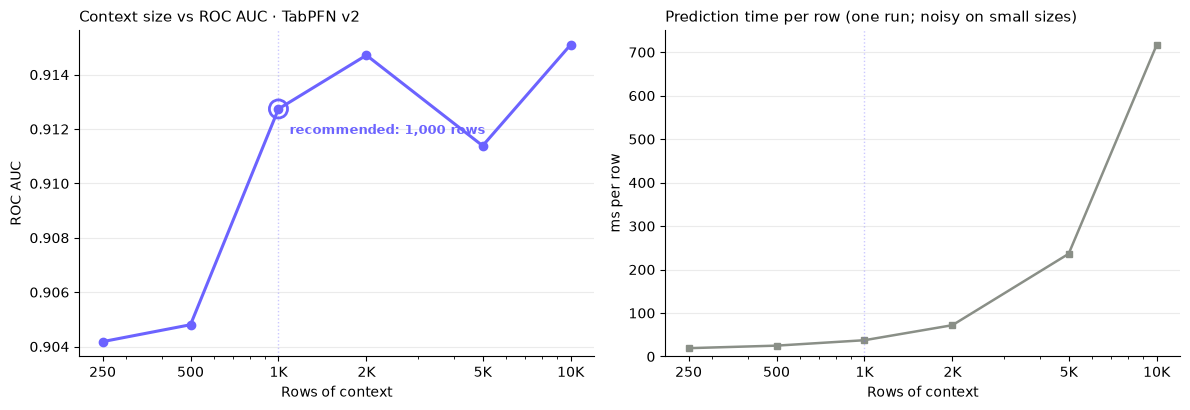

In [12]:
curve.plot();

On a capability, `cap.context_curve(test)` runs the same curve on its champion and its own context, and `cap.update(context_rows=curve.recommended)` keeps the smaller, faster context for predictions.

## Next

* Pick the competitors: `ZeroGrad(models=["tabpfn-v2", "mitra-v2"])` (Mitra-v2 needs `pip install "zerograd[mitra]"`).
* Run it in production with versions, scheduled championships, monitoring and Explain: `ZeroGrad(remote=True)` on [zerograd.dev](https://zerograd.dev).
* Licenses: TabPFN v2 asks products built with it to show *Built with PriorLabs-TabPFN*. See `MODELS.md` and `TERMS.md`.